In [1]:
import pandas as pd

df = pd.read_csv("data/subway_congestion.csv", encoding="cp949")
df.head()

,구분,호선,역번호,역명,상하구분,5시30분,6시00분,6시30분,7시00분,7시30분,...,20시00분,20시30분,21시00분,21시30분,22시00분,22시30분,23시00분,23시30분,00시00분,00시30분
0,평일,1호선,150,서울역,상선,8.9,21.2,22.7,41.3,72.1,...,18.3,17.9,19.3,16.0,16.4,17.2,13.6,8.9,7.1,1.6
1,평일,1호선,150,서울역,하선,11.5,11.2,16.4,22.4,40.2,...,40.5,40.4,42.5,38.6,38.6,31.0,18.6,13.7,9.7,0.0
2,평일,1호선,151,시청,상선,7.3,15.8,18.2,30.6,54.8,...,21.8,22.1,22.3,21.1,20.7,20.0,17.8,10.2,7.5,1.6
3,평일,1호선,151,시청,하선,9.2,10.4,17.0,21.9,36.7,...,36.2,37.8,41.1,31.9,34.5,26.9,17.2,12.7,6.7,0.4
4,평일,1호선,152,종각,상선,6.8,14.6,11.4,20.0,31.9,...,28.2,28.8,30.3,27.7,27.4,26.4,24.4,12.8,8.4,1.5


In [2]:
# 시간대 컬럼 선택
time_cols = df.columns[5:]

# 각 행의 평균 혼잡도 계산
df["평균혼잡도"] = df[time_cols].mean(axis=1)

# 호선별 평균 혼잡도 계산
line_avg = df.groupby("호선")["평균혼잡도"].mean()

line_avg

호선
1호선    27.233846
2호선    32.877968
3호선    25.958371
4호선    31.203008
5호선    26.869458
6호선    23.836544
7호선    31.615140
8호선    29.650270
Name: 평균혼잡도, dtype: float64

In [3]:
# 평균 혼잡도가 높은 순서로 정렬
line_rank = line_avg.sort_values(ascending=False)

# 소수점 둘째 자리까지 표시
line_rank.round(2)

호선
2호선    32.88
7호선    31.62
4호선    31.20
8호선    29.65
1호선    27.23
5호선    26.87
3호선    25.96
6호선    23.84
Name: 평균혼잡도, dtype: float64

In [4]:
# 가장 혼잡한 호선
print("가장 혼잡한 호선:", line_rank.idxmax())
print("평균 혼잡도:", round(line_rank.max(), 2), "%")

# 가장 한산한 호선
print("가장 한산한 호선:", line_rank.idxmin())
print("평균 혼잡도:", round(line_rank.min(), 2), "%")

가장 혼잡한 호선: 2호선
평균 혼잡도: 32.88 %
가장 한산한 호선: 6호선
평균 혼잡도: 23.84 %


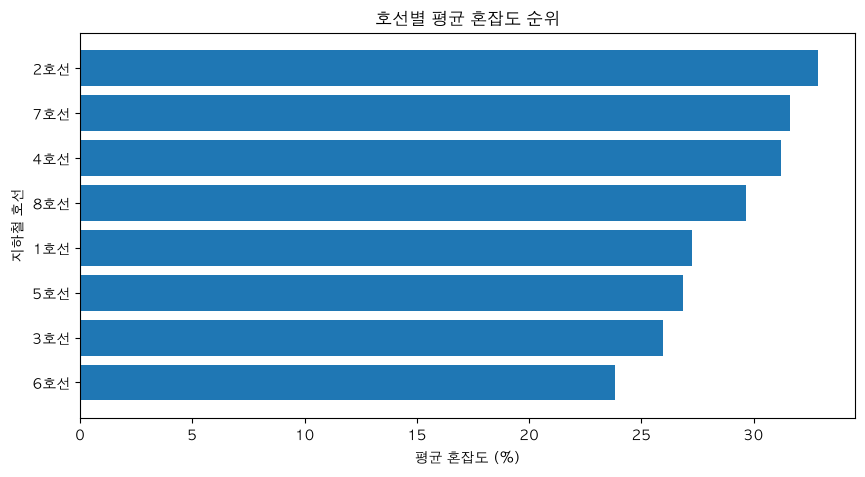

In [5]:
import matplotlib.pyplot as plt

# 맥북 한글 폰트 설정
plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

# 평균 혼잡도 높은 순서로 정렬
line_rank = line_avg.sort_values(ascending=False)

# 가로 막대그래프 생성
plt.figure(figsize=(10, 5))

plt.barh(line_rank.index, line_rank.values)

# 혼잡도가 높은 호선이 위쪽에 오도록 설정
plt.gca().invert_yaxis()

# 그래프 제목 및 축 이름
plt.title("호선별 평균 혼잡도 순위")
plt.xlabel("평균 혼잡도 (%)")
plt.ylabel("지하철 호선")

plt.show()

In [6]:
# 30분 단위 시간대 컬럼 선택
time_cols = df.columns[5:44]

# 시간대별 평균 혼잡도 계산
time_avg = df[time_cols].mean()

# 소수점 둘째 자리까지 출력
time_avg.round(2)

5시30분     16.44
6시00분     16.42
6시30분     16.02
7시00분     21.11
7시30분     27.09
8시00분     34.03
8시30분     32.41
9시00분     32.72
9시30분     31.03
10시00분    29.39
10시30분    29.66
11시00분    30.14
11시30분    30.14
12시00분    30.58
12시30분    33.21
13시00분    33.45
13시30분    33.10
14시00분    32.47
14시30분    33.07
15시00분    34.23
15시30분    36.33
16시00분    38.61
16시30분    40.97
17시00분    42.16
17시30분    41.89
18시00분    42.51
18시30분    39.12
19시00분    32.34
19시30분    28.97
20시00분    27.79
20시30분    28.27
21시00분    28.34
21시30분    27.07
22시00분    27.69
22시30분    24.33
23시00분    20.64
23시30분    14.82
00시00분     4.57
00시30분     1.79
dtype: float64

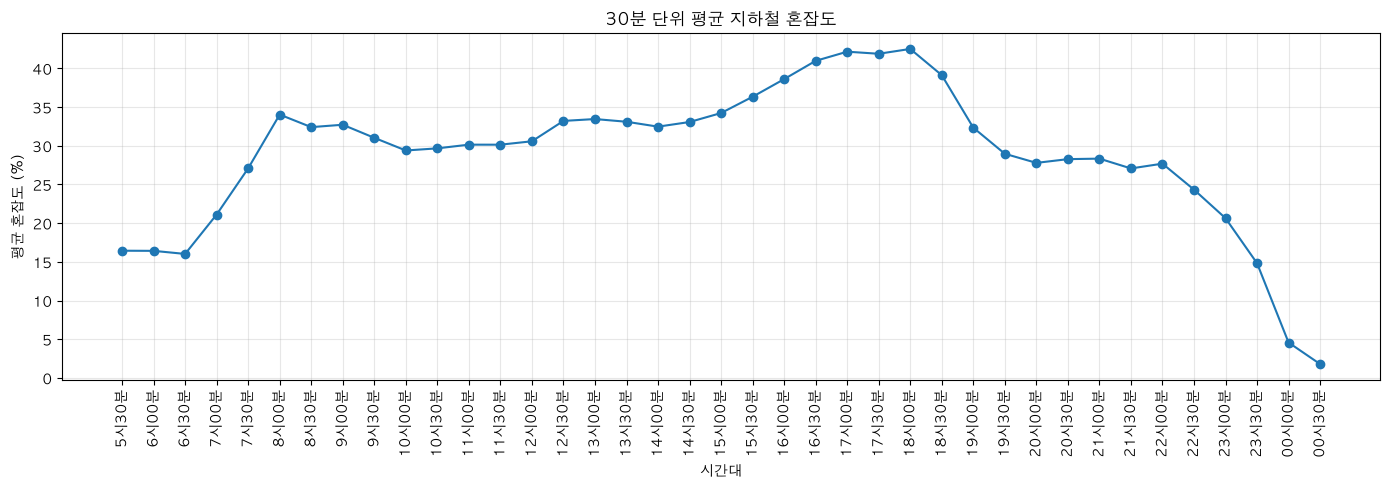

In [7]:
# 30분 단위 평균 혼잡도 선그래프
plt.figure(figsize=(14, 5))
plt.plot(time_avg.index, time_avg.values, marker="o")

plt.title("30분 단위 평균 지하철 혼잡도")
plt.xlabel("시간대")
plt.ylabel("평균 혼잡도 (%)")

plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
# 평일 데이터만 선택
weekday_df = df[df["구분"] == "평일"]

# 출퇴근 시간대 설정
morning_cols = ["7시00분", "7시30분", "8시00분", "8시30분"]
evening_cols = ["18시00분", "18시30분", "19시00분", "19시30분"]

# 출퇴근 평균 혼잡도 계산
morning_avg = weekday_df[morning_cols].mean().mean()
evening_avg = weekday_df[evening_cols].mean().mean()

# 결과 출력
print(f"출근 시간 평균 혼잡도: {morning_avg:.2f}%")
print(f"퇴근 시간 평균 혼잡도: {evening_avg:.2f}%")

출근 시간 평균 혼잡도: 49.04%
퇴근 시간 평균 혼잡도: 46.46%


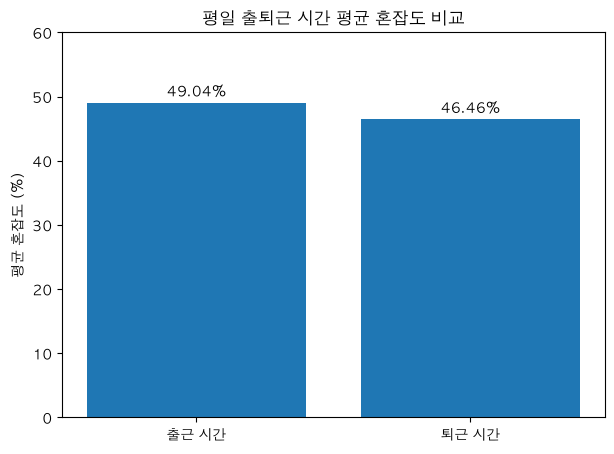

In [9]:
# 출퇴근 혼잡도 비교
labels = ["출근 시간", "퇴근 시간"]
values = [morning_avg, evening_avg]

plt.figure(figsize=(7, 5))
bars = plt.bar(labels, values)

plt.title("평일 출퇴근 시간 평균 혼잡도 비교")
plt.ylabel("평균 혼잡도 (%)")
plt.ylim(0, 60)

# 막대 위에 평균 혼잡도 표시
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.2f}%",
        ha="center"
    )

plt.show()

In [10]:
# 가장 혼잡한 시간대
print("가장 혼잡한 시간대:", time_avg.idxmax())
print(f"평균 혼잡도: {time_avg.max():.2f}%")

# 가장 한산한 시간대
print("가장 한산한 시간대:", time_avg.idxmin())
print(f"평균 혼잡도: {time_avg.min():.2f}%")

가장 혼잡한 시간대: 18시00분
평균 혼잡도: 42.51%
가장 한산한 시간대: 00시30분
평균 혼잡도: 1.79%
